In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

In [3]:
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [4]:
DATASET_PATH = r"C:\Users\Prajakta\Downloads\face-mask-detection\dataset"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32

In [5]:
train_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    interpolation="nearest"
)

val_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_PATH,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb",
    interpolation="nearest"
)

class_names = train_data.class_names

print("Classes:", class_names)

Found 2079 files belonging to 3 classes.
Using 1664 files for training.
Found 2079 files belonging to 3 classes.
Using 415 files for validation.
Classes: ['incorrect_mask', 'with_mask', 'without_mask']


In [6]:
train_data = train_data.map(
    lambda images, labels: (
        tf.cast(images, tf.float32) / 255.0,
        labels
    )
)

val_data = val_data.map(
    lambda images, labels: (
        tf.cast(images, tf.float32) / 255.0,
        labels
    )
)

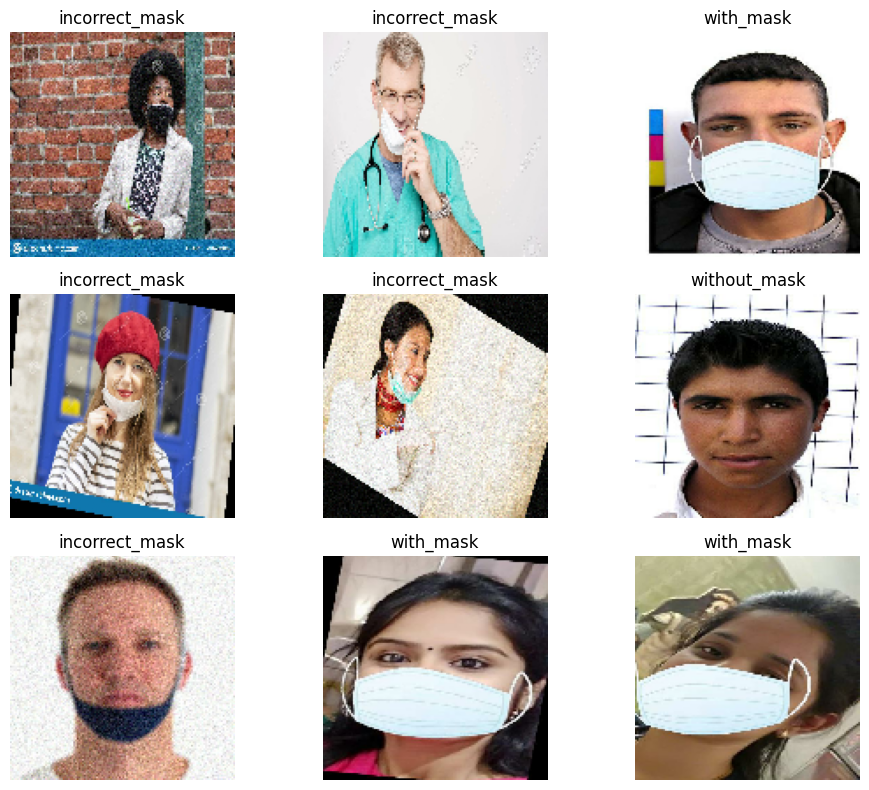

In [7]:
plt.figure(figsize=(10, 8))

for images, labels in train_data.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy())
        plt.title(class_names[labels[i].numpy()])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(3, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 126, 126, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 63, 63, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 61, 61, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 30, 30, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 28, 28, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 14, 14, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 25088)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │       3,211,392 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │             387 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 3,305,027 (12.61 MB)

 Trainable params: 3,305,027 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [10]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10


C:\Users\Prajakta\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


52/52 ━━━━━━━━━━━━━━━━━━━━ 20s 328ms/step - accuracy: 0.6755 - loss: 0.7595 - val_accuracy: 0.8795 - val_loss: 0.3308
Epoch 2/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 324ms/step - accuracy: 0.8774 - loss: 0.3432 - val_accuracy: 0.9060 - val_loss: 0.2586
Epoch 3/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 315ms/step - accuracy: 0.9213 - loss: 0.2237 - val_accuracy: 0.9325 - val_loss: 0.1942
Epoch 4/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 316ms/step - accuracy: 0.9375 - loss: 0.1813 - val_accuracy: 0.9446 - val_loss: 0.1447
Epoch 5/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 316ms/step - accuracy: 0.9453 - loss: 0.1555 - val_accuracy: 0.9494 - val_loss: 0.1482
Epoch 6/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 317ms/step - accuracy: 0.9712 - loss: 0.1009 - val_accuracy: 0.9494 - val_loss: 0.1406
Epoch 7/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 314ms/step - accuracy: 0.9748 - loss: 0.0832 - val_accuracy: 0.9422 - val_loss: 0.1349
Epoch 8/10
52/52 ━━━━━━━━━━━━━━━━━━━━ 17s 325ms/step - accuracy: 0.9802 - loss: 0.0623 - val_accuracy: 0.978

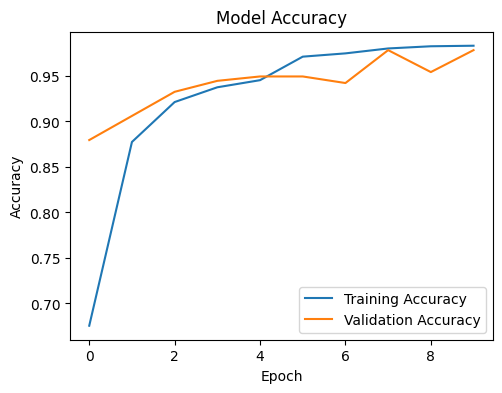

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()


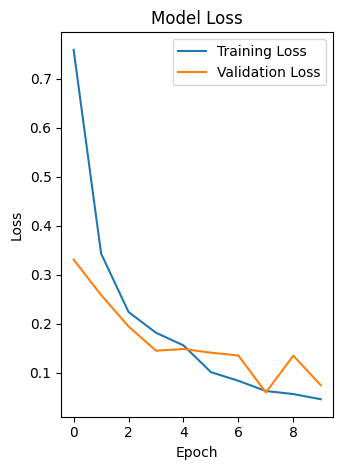

In [12]:
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [13]:
val_loss, val_accuracy = model.evaluate(val_data)

print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy * 100, 2), "%")

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 123ms/step - accuracy: 0.9783 - loss: 0.0742
Validation Loss: 0.0742
Validation Accuracy: 97.83 %


In [14]:
y_true = []
y_pred = []

for images, labels in val_data:
    predictions = model.predict(images, verbose=0)

    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

                precision    recall  f1-score   support

incorrect_mask       0.99      0.97      0.98       124
     with_mask       0.96      0.98      0.97       127
  without_mask       0.98      0.98      0.98       164

      accuracy                           0.98       415
     macro avg       0.98      0.98      0.98       415
  weighted avg       0.98      0.98      0.98       415



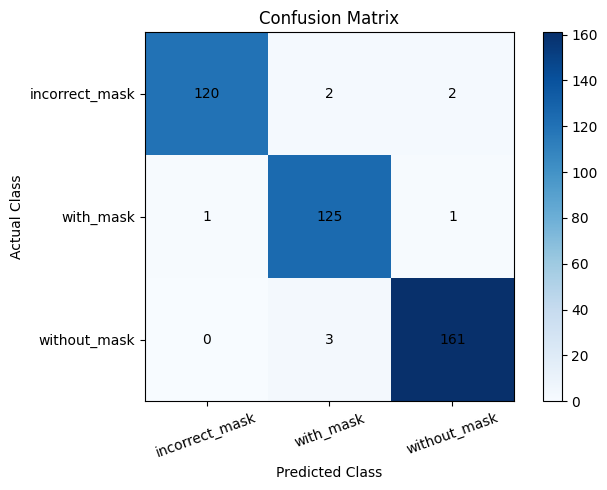

In [15]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(range(3), class_names, rotation=20)
plt.yticks(range(3), class_names)
plt.colorbar()

for i in range(3):
    for j in range(3):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

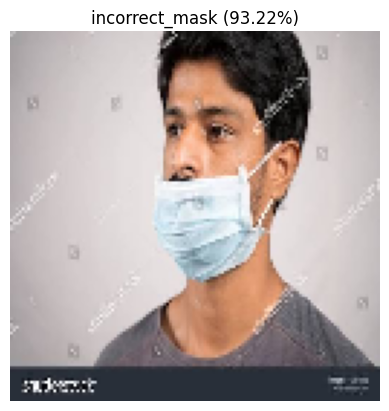

Predicted Class: incorrect_mask
Confidence: 93.22 %


In [16]:
from tensorflow.keras.utils import load_img, img_to_array

IMAGE_PATH = r"C:\Users\Prajakta\Downloads\test_image\person.jpg"

img = load_img(
    IMAGE_PATH,
    target_size=(128, 128),
    interpolation="nearest"
)

img_array = img_to_array(img) / 255.0
img_array = np.expand_dims(img_array, axis=0)

prediction = model.predict(img_array, verbose=0)[0]

predicted_index = np.argmax(prediction)
predicted_class = class_names[predicted_index]
confidence = prediction[predicted_index] * 100

plt.imshow(img)
plt.axis("off")
plt.title(f"{predicted_class} ({confidence:.2f}%)")
plt.show()

print("Predicted Class:", predicted_class)
print("Confidence:", round(confidence, 2), "%")

In [17]:
for i, class_name in enumerate(class_names):
    print(f"{class_name}: {prediction[i] * 100:.2f}%")

incorrect_mask: 93.22%
with_mask: 6.75%
without_mask: 0.02%
